<a href="https://colab.research.google.com/github/KigbuAnne/Air-BNB-2019/blob/main/Group_A_EDA_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

IMPORTING LIBRARIES



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.m.ount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
customers_df=pd.read_csv('/content/drive/MyDrive/olist_customers_dataset.csv')

In [ ]:
orders = pd.read_csv('/content/drive/MyDrive/olist_orders_dataset.csv')
order_items = pd.read_csv('/content/drive/MyDrive/olist_order_items_dataset.csv')
payments = pd.read_csv('/content/drive/MyDrive/olist_order_payments_dataset.csv')
products = pd.read_csv('/content/drive/MyDrive/olist_products_dataset.csv')

In Python, datasets must be explicitly merged using keys to create a unified dataset for analysis, unlike tools like Power BI where relationships can be defined without physically combining tables.


In [ ]:
merged_df = pd.merge(customers_df, orders, on='Customer_Id')
print(merged_df.head())

                        Customer_Id                Customer_Unique_Id  \
0  06b8999e2fba1a1fbc88172c00ba8bc7  861eff4711a542e4b93843c6dd7febb0   
1  4e7b3e00288586ebd08712fdd0374a03  060e732b5b29e8181a18229c7b0b2b5e   
2  b2b6027bc5c5109e529d4dc6358b12c3  259dac757896d24d7702b9acbbff3f3c   
3  4f2d8ab171c80ec8364f7c12e35b23ad  345ecd01c38d18a9036ed96c73b8d066   
4  879864dab9bc3047522c92c82e1212b8  4c93744516667ad3b8f1fb645a3116a4   

   Customer_Zip_Code    Customer_City Customer_State  \
0              14409           Franca             SP   
1               1151        Sao Paulo             SP   
2               8775  Mogi Das Cruzes             SP   
3              13056         Campinas             SP   
4              89254   Jaragua Do Sul             SC   

                           Order_Id Order_Status Order_Purchase_Date  \
0  00e7ee1b050b8499577073aeb2a297a1    delivered     5/16/2017 15:05   
1  b2059ed67ce144a36e2aa97d2c9e9ad2    delivered     5/19/2018 16:07   
2  95167

In [ ]:
merged_df = pd.merge(merged_df, order_items, on='Order_Id')

In [ ]:
#Merge payments
merged_df = pd.merge(merged_df, payments, on='Order_Id')

In [ ]:
#Find all duplicate rows
merged_df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
101121,False
101122,False
101123,False
101124,False


In [ ]:
#Count duplicates
merged_df.duplicated().sum()

np.int64(0)

In [ ]:
merged_df.head(10)

,Customer_Id,Customer_Unique_Id,Customer_Zip_Code,Customer_City,Customer_State,Order_Id,Order_Status,Order_Purchase_Date,Order_Approved_Date,Order_Delivered_Carrier_Date,...,Seller_Id,Shipping_Limit_Date,Price,Freight_Value,Total_Cost,Payment_No,Payment_Type,Payment_Installments,Payment_Value,Average_Payment_Installment
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,Franca,SP,00e7ee1b050b8499577073aeb2a297a1,delivered,5/16/2017 15:05,5/16/2017 15:22,5/23/2017 10:47,...,7c67e1448b00f6e969d365cea6b010ab,5/22/2017 15:22,124.99,21.88,146.87,1.0,Credit_Card,1.0,101.14,101.14
1,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,Sao Paulo,SP,b2059ed67ce144a36e2aa97d2c9e9ad2,delivered,5/19/2018 16:07,5/20/2018 16:19,06/11/2018 14:31,...,7c67e1448b00f6e969d365cea6b010ab,6/5/2018 16:19,139.94,17.79,157.73,1.0,Boleto,1.0,96.00,96.00
2,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,Mogi Das Cruzes,SP,951670f92359f4fe4a63112aa7306eba,delivered,3/13/2018 16:06,3/13/2018 17:29,3/27/2018 23:22,...,7c67e1448b00f6e969d365cea6b010ab,3/27/2018 16:31,149.94,23.36,173.30,1.0,Credit_Card,1.0,60.08,60.08
3,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,Campinas,SP,6b7d50bd145f6fc7f33cebabd7e49d0f,delivered,7/29/2018 9:51,7/29/2018 10:10,7/30/2018 15:16,...,4a3ca9315b744ce9f8e9374361493884,7/31/2018 10:10,230.00,22.25,252.25,1.0,Credit_Card,1.0,38.68,38.68
4,879864dab9bc3047522c92c82e1212b8,4c93744516667ad3b8f1fb645a3116a4,89254,Jaragua Do Sul,SC,5741ea1f91b5fbab2bd2dc653a5b5099,delivered,9/14/2017 18:14,9/14/2017 18:25,9/18/2017 21:27,...,8f2ce03f928b567e3d56181ae20ae952,9/20/2017 18:25,259.90,22.31,282.21,1.0,Credit_Card,3.0,38.55,12.85
5,fd826e7cf63160e536e0908c76c3f441,addec96d2e059c80c30fe6871d30d177,4534,Sao Paulo,SP,36e694cf4cbc2a4803200c35e84abdc4,delivered,2/19/2018 14:38,2/19/2018 14:50,2/20/2018 0:03,...,9f505651f4a6abe901a56cdc21508025,2/23/2018 14:50,14.99,7.78,22.77,1.0,Credit_Card,1.0,57.68,57.68
6,5e274e7a0c3809e14aba7ad5aae0d407,57b2a98a409812fe9618067b6b8ebe4f,35182,Timoteo,MG,1093c8304c7a003280dd34598194913d,delivered,11/16/2017 19:29,11/16/2017 19:55,11/22/2017 16:46,...,2a7dc43cecabf23403078e2188437d1d,11/22/2017 19:55,19.90,16.11,36.01,1.0,Credit_Card,1.0,38.24,38.24
7,5adf08e34b2e993982a47070956c5c65,1175e95fb47ddff9de6b2b06188f7e0d,81560,Curitiba,PR,1ebeea841c590e86a14a0d7a48e7d062,delivered,1/18/2018 12:35,1/18/2018 12:56,1/18/2018 23:25,...,95e03ca3d4146e4011985981aeb959b9,1/30/2018 12:56,25.00,14.10,39.10,1.0,Credit_Card,3.0,78.10,26.03
8,4b7139f34592b3a31687243a302fa75b,9afe194fb833f79e300e37e580171f22,30575,Belo Horizonte,MG,7433cbcc783205509d66a5260da5b574,delivered,01/08/2018 11:22,01/08/2018 11:35,01/11/2018 01:00,...,0241d4d5d36f10f80c644447315af0bd,1/12/2018 11:35,99.90,22.57,122.47,1.0,Credit_Card,3.0,34.09,11.36
9,9fb35e4ed6f0a14a4977cd9aea4042bb,2a7745e1ed516b289ed9b29c7d0539a5,39400,Montes Claros,MG,8428e578bb1cf839ae26a6b7615502b9,delivered,11/27/2017 17:23,11/27/2017 18:01,11/28/2017 23:04,...,b6e1504972665f739dec4facb9943775,12/1/2017 18:01,25.30,15.10,40.40,1.0,Credit_Card,1.0,40.40,40.40


In [ ]:
merged_df.describe()

,Customer_Zip_Code,Order_Item_Id,Price,Freight_Value,Total_Cost,Payment_No,Payment_Installments,Payment_Value
count,101126.000000,101126.000000,101126.000000,101126.000000,101126.000000,101126.000000,101126.000000,101126.000000
mean,35140.939036,1.194114,120.800042,20.001109,140.801150,1.092736,2.858315,154.746039
std,29862.693808,0.686061,184.797173,15.782647,191.793214,0.716814,2.689061,217.947807
min,1003.000000,1.000000,0.850000,0.000000,6.080000,1.000000,0.000000,0.000000
25%,11356.250000,1.000000,39.900000,13.080000,55.252500,1.000000,1.000000,56.780000
50%,24342.000000,1.000000,74.900000,16.260000,92.180000,1.000000,1.000000,100.000000
75%,59054.000000,1.000000,134.900000,21.150000,158.070000,1.000000,4.000000,172.960000
max,99990.000000,21.000000,6735.000000,409.680000,6929.310000,29.000000,24.000000,13664.080000


In [ ]:
 #Total Revenue
merged_df['Payment_Value'].sum()

np.float64(15648847.889999999)

In [ ]:
#Total Orders
merged_df['Order_Id'].nunique()

88680

**EXPLORATORY DATA ANAYSIS OF DATA**

**INSIGHT GENERATION**

We are expected to answer the following business questions.


*   What patterns exist in the data?
*   What is driving revenue?
*   Which areas are underperforming?
*   What anomalies or issues do you observe?





**REVENUE BY CATEGORY**

In [ ]:
# Top performing products by revenue
top_products = merged_df.groupby('Product_Category')['Payment_Value'].sum().sort_values(ascending=False)
print(top_products.head(10)) # Display top 10

Product_Category
cama_mesa_banho           1548530.07
beleza_saude              1384223.55
esporte_lazer             1189953.46
moveis_decoracao          1173942.32
informatica_acessorios    1093495.78
utilidades_domesticas      947451.18
relogios_presentes         818676.01
telefonia                  613647.25
ferramentas_jardim         595420.35
automotivo                 578842.46
Name: Payment_Value, dtype: float64


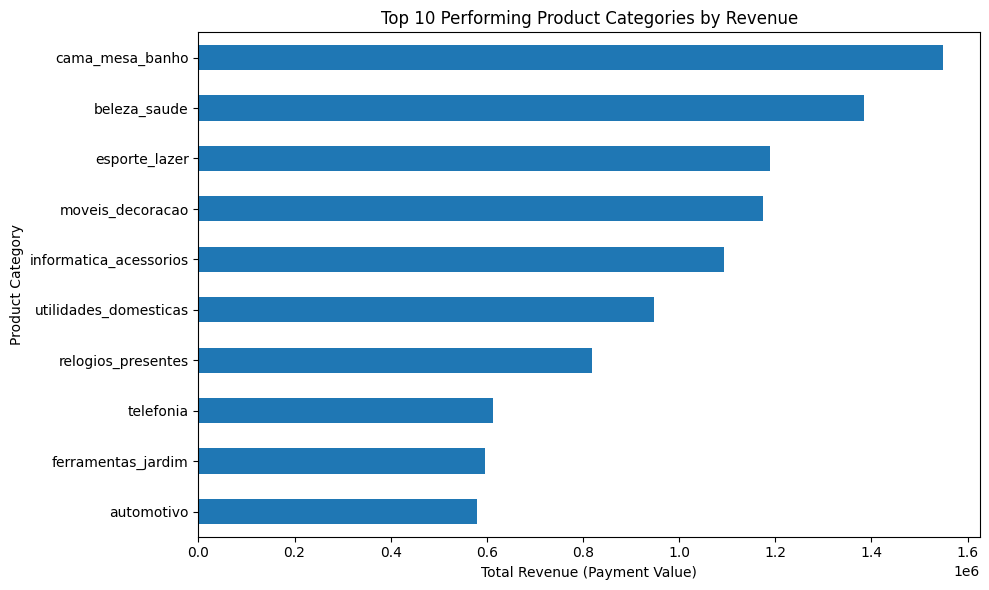

In [ ]:
top_products.head(10).plot(kind='barh', figsize=(10, 6))
plt.title('Top 10 Performing Product Categories by Revenue')
plt.xlabel('Total Revenue (Payment Value)')
plt.ylabel('Product Category')
plt.gca().invert_yaxis() # To display the highest value at the top
plt.tight_layout()
plt.show()

The table and bar chart show that a small number of products dominate total sales, contributing a disproportionately large share of revenue compared to the rest of the products

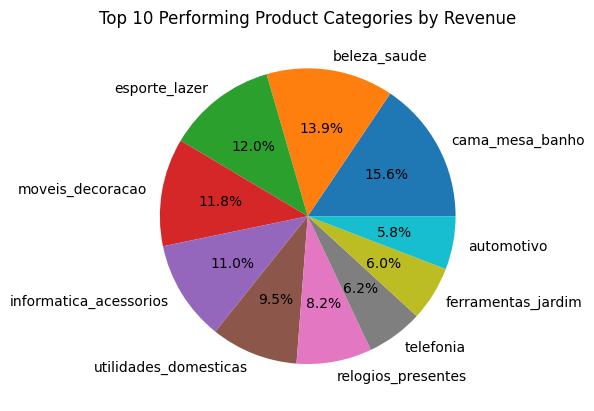

In [ ]:
# Ensure merged_df is defined with Product_Category before calculating top_products
merged_df = pd.merge(customers_df, orders, on='Customer_Id')
merged_df = pd.merge(merged_df, order_items, on='Order_Id')
merged_df = pd.merge(merged_df, payments, on='Order_Id')
merged_df = pd.merge(merged_df, products[['Product_Id', 'Product_Category']], on='Product_Id', how='left')

# Calculate top_products
top_products = merged_df.groupby('Product_Category')['Payment_Value'].sum().sort_values(ascending=False)

plt.figure()

# Use top_products.head(10) to plot the top 10 categories
plt.pie(
    top_products.head(10),
    labels=top_products.head(10).index,
    autopct='%1.1f%%'
)

plt.title('Top 10 Performing Product Categories by Revenue')

plt.show()


**REVENUE BY STATE**

In [ ]:
# Merge dataframes to create merged_df
merged_df = pd.merge(customers_df, orders, on='Customer_Id')
merged_df = pd.merge(merged_df, order_items, on='Order_Id')
merged_df = pd.merge(merged_df, payments, on='Order_Id')
merged_df = pd.merge(merged_df, products[['Product_Id', 'Product_Category']], on='Product_Id', how='left')

# Perform the requested operation
merged_df.groupby('Customer_State')['Order_Id'].nunique().sort_values(ascending=False)

,Order_Id
Customer_State,
SP,37167
RJ,11500
MG,10376
RS,4864
PR,4477
SC,3270
BA,3012
DF,1888
ES,1825


Similarly,we can see that in the top 3 states above,majority of the orders are found, this implies that a large proportion of customers are from there.


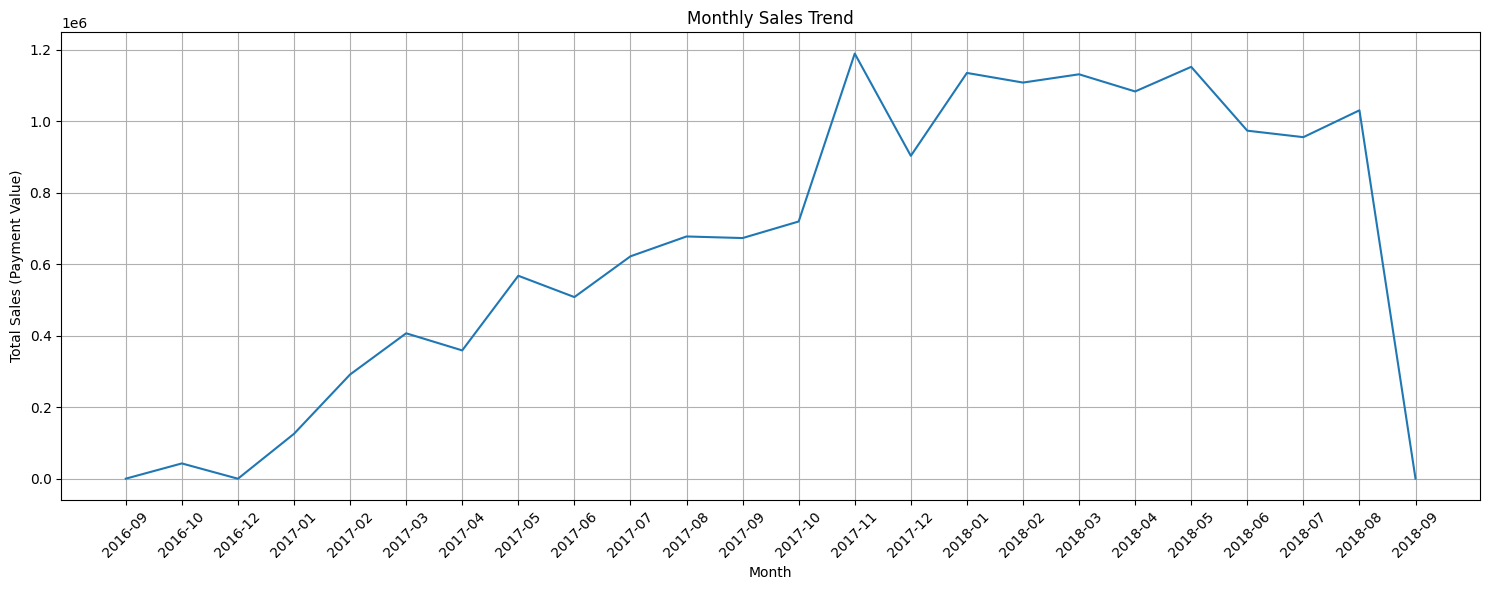

In [ ]:
from datetime import time

# Convert 'Order_Purchase_Date' to datetime objects
merged_df['Order_Purchase_Date'] = pd.to_datetime(merged_df['Order_Purchase_Date'], errors='coerce')

# Extract year and month for sales trend analysis
merged_df['YearMonth'] = merged_df['Order_Purchase_Date'].dt.to_period('M')

# Calculate monthly sales
monthly_sales = merged_df.groupby('YearMonth')['Payment_Value'].sum().reset_index()
monthly_sales['YearMonth'] = monthly_sales['YearMonth'].astype(str)

# Plot the sales trend
plt.figure(figsize=(15, 6))
sns.lineplot(data=monthly_sales, x='YearMonth', y='Payment_Value')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales (Payment Value)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


The sales trend shows a clear upward movement over time, combined with recurring seasonal patterns where revenue peaks during specific periods

Customer Distribution

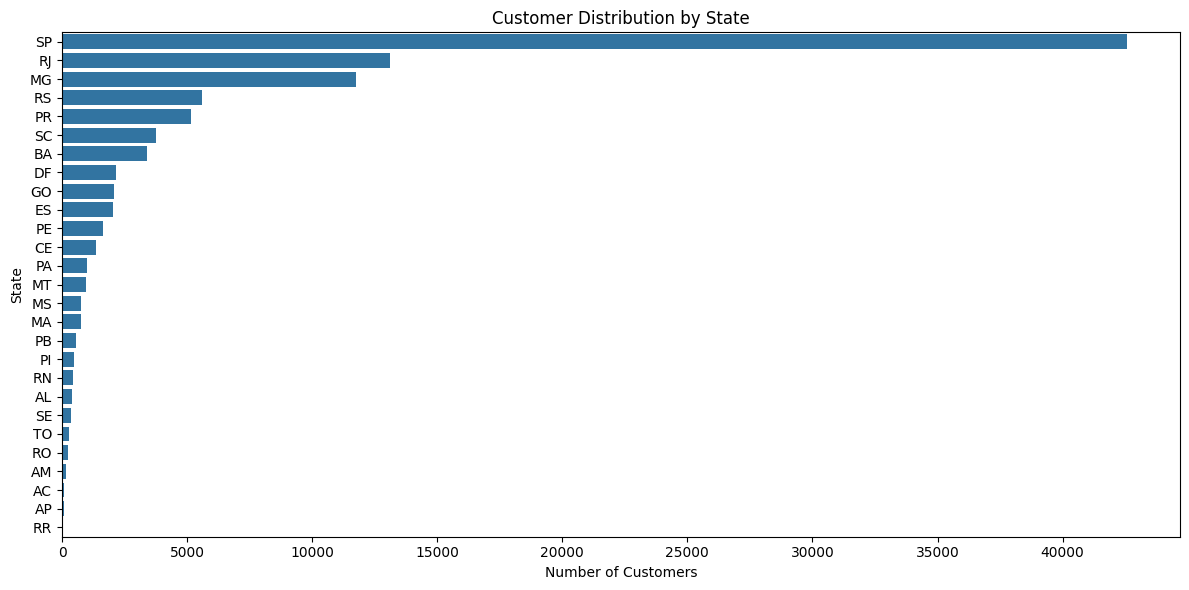

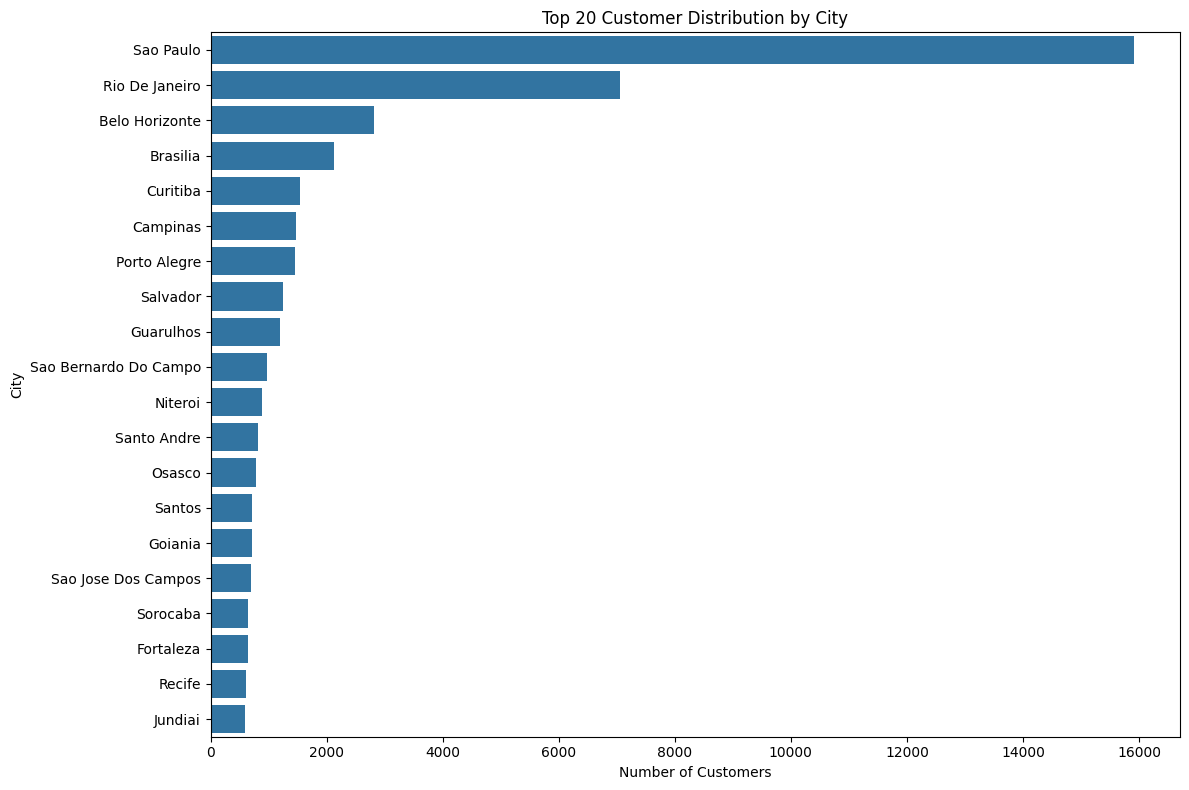

In [ ]:
# To visualize customer distributions, we can look at the distribution of customers by state or city.

# Distribution of customers by state
plt.figure(figsize=(12, 6))
sns.countplot(data=merged_df, y='Customer_State', order=merged_df['Customer_State'].value_counts().index)
plt.title('Customer Distribution by State')
plt.xlabel('Number of Customers')
plt.ylabel('State')
plt.tight_layout()
plt.show()

# Distribution of customers by city (top 20)
plt.figure(figsize=(12, 8))
sns.countplot(data=merged_df, y='Customer_City', order=merged_df['Customer_City'].value_counts().head(20).index)
plt.title('Top 20 Customer Distribution by City')
plt.xlabel('Number of Customers')
plt.ylabel('City')
plt.tight_layout()
plt.show()

PAYMENT INSIGHTS


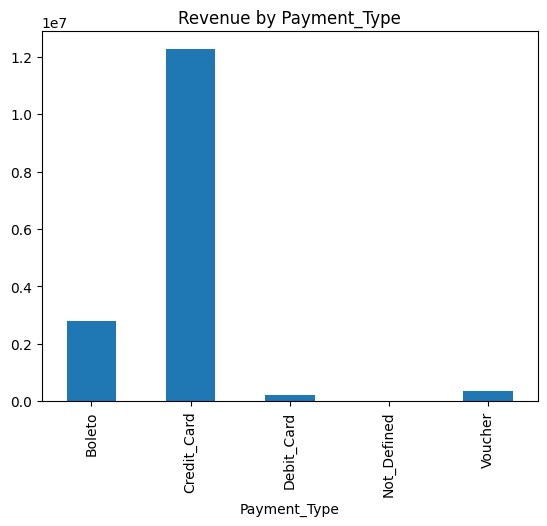

In [ ]:
payment_method = merged_df.groupby("Payment_Type")["Payment_Value"].sum()

payment_method.plot(kind='bar')
plt.title("Revenue by Payment_Type")
plt.show()

Credit card is the dominant payment method, contributing the highest share of transactions or revenue compared to other payment options.

**DELIVERY PERFORMANCE**

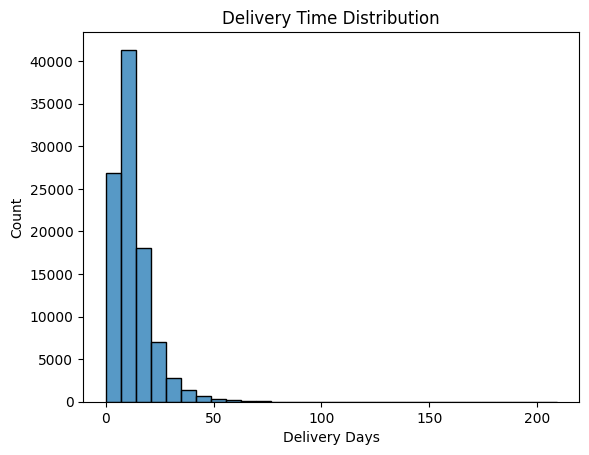

In [ ]:
merged_df['Order_Delivered_date'] = pd.to_datetime(merged_df['Order_Delivered_date'], errors='coerce')
merged_df['Order_Purchase_Date'] = pd.to_datetime(merged_df['Order_Purchase_Date'], errors='coerce')

merged_df['delivery_days'] = (merged_df['Order_Delivered_date'] - merged_df['Order_Purchase_Date']).dt.days

merged_df['delivery_days'].describe()
sns.histplot(merged_df['delivery_days'], bins=30)
plt.title('Delivery Time Distribution')
plt.xlabel('Delivery Days')
plt.ylabel('Count')
plt.show()

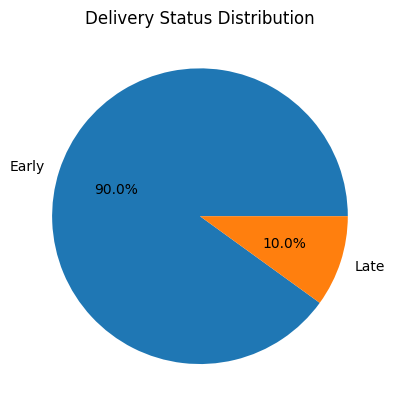

In [ ]:
delivery_counts = merged_df['Delivery_Status'].value_counts()

plt.figure()

plt.pie(
    delivery_counts,
    labels=delivery_counts.index,
    autopct='%1.1f%%'
)

plt.title('Delivery Status Distribution')
plt.show()

The distribution of delivery times indicates that approximately 90% of orders are delivered earlier than the expected delivery date, suggesting a strong logistics performance


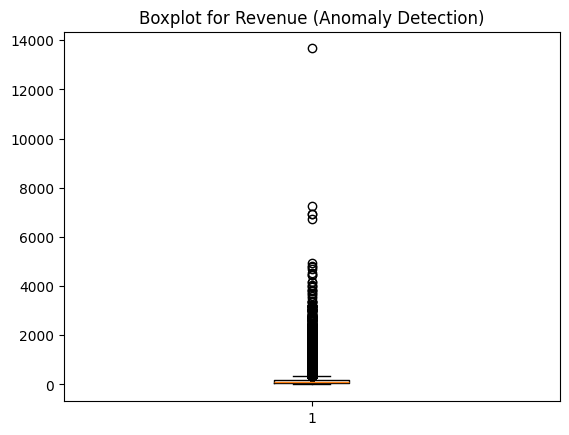

In [ ]:
plt.figure()
plt.boxplot(merged_df['Payment_Value'])
plt.title('Boxplot for Revenue (Anomaly Detection)')
plt.show()

The boxplot reveals significant outliers in order values, including unusually high transactions and zero-value orders, indicating the presence of anomalies in the dataset.



In [ ]:
product_sales = merged_df.groupby('Product_Id')['Payment_Value'].sum().sort_values(ascending=False)

top_10_percent = int(len(product_sales) * 0.1)

top_contribution = product_sales.head(top_10_percent).sum() / product_sales.sum()

print("Top 10% products contribute:", top_contribution)

Top 10% products contribute: 0.5835098305118743


In [ ]:
product_sales = merged_df.groupby('Product_Id')['Payment_Value'].sum().sort_values(ascending=False)

top_20_percent = int(len(product_sales) * 0.2)

top_contribution = product_sales.head(top_20_percent).sum() / product_sales.sum()

print("Top 20% products contribute:", top_contribution)

Top 20% products contribute: 0.7303828409824233


The revenue distribution is highly concentrated: the top 10  products generate 58% of total revenue, while the top 20 account for 73%. This indicates a strong Pareto effect, where a small subset of products drives the majority of business performance.

**KEY INSIGHTS**

1. Revenue Concentration Risk

Exploratory Data Analysis reveals that revenue is highly concentrated among a small number of product categories—particularly cama_mesa_banho, beleza_saude, esporte_lazer, and two others. Collectively, these top five categories generate a significant share of total revenue. This indicates a strong dependency on a limited product range, exposing the business to potential risk if demand for these products declines. Interestingy, a few states also account for the majority of orders and revenue, reinforcing this concentration pattern geographically.

2. Sales Trend and Seasonality


The dataset exhibits both an upward trend and clear seasonality. Sales steadily increased from 2016 through March 2017, followed by noticeable spikes, particularly in May and a peak in November 2017. This pattern suggests that customer purchasing behavior is influenced by specific periods, likely tied to promotions, holidays, or seasonal demand.

 3. Uneven Market Penetration Across States

There is a significant disparity in performance across states. While a few states drive the bulk of orders and revenue, a larger number—approximately 12 states—are underperforming. This imbalance highlights uneven market penetration and suggests untapped opportunities in low-performing regions, as well as potential issues related to accessibility, awareness, or logistics.

4.  Customer Payment Preferences

Payment behavior shows a clear preference for credit card transactions, which account for the highest transaction value. Other methods such as boleto, debit card, and vouchers are used less frequently. This insight can guide payment optimization strategies and promotional offers tailored to customer preferences.

5. High Rate of Early Deliveries

Approximately 90% of orders are delivered earlier than expected, indicating strong logistics performance and operational efficiency. While this is a positive indicator, maintaining or slightly optimizing delivery timing could further enhance customer satisfaction and cost efficiency.

6. Presence of Anomalies in Payment Values

The dataset contains notable anomalies in payment values, including unusually high transactions (e.g., 8,000–14,000) and some records with zero value. These irregularities may indicate data quality issues, bulk orders, or system errors, and should be investigated further to ensure accurate analysis and reporting.

**BUSSINESS RECOMMENDATION**

1. We recommend that our company invests more on the top selling products through adverts,promos and research to constantly improve upon  the products.
2. Reduce dependency on a few products by diversifying and expanding the top selling products category.
3. Run target campaigns before peak periods to increase consumer buying behavior.
4. Encourage higher purchases by providing incentives, rewards and promos during peak periods.
5. In high performing states, increase marketing in order to boost orders and revenue. However, we need to ask this question?, "Why are  there  abnormally low sales in 12  States?" . In this case,we might use the 5 why's to investigate this, we highly recommend an investigation that will help us understand the low performance in a wide number of states.We would also consider specific promos to enhance buying performance.
6. We need to ensure that we optimise Credit_Card paying method and make it seamless and hassle free. We can also offer incentives for faster payments in the form of discounts. To encourage other payment methods, we can give incentives to Boleto payment.

**CONCLUSION**


The analysis clearly shows that Goshen Commerce Ltd’s revenue is heavily driven by a small subset of its product portfolio, with just 20% of products contributing approximately 73% of total revenue. This highlights a strong comparative advantage within these high-performing categories and presents an opportunity for strategic focus.

To maximize growth and efficiency, the company should prioritize investment, marketing, and inventory optimization around these top-performing products. At the same time, it is critical to evaluate and improve or streamline underperforming products to reduce unnecessary costs and operational inefficiencies.

However, this concentration also introduces a level of risk. Over-reliance on a limited number of products makes the business vulnerable to market shifts, changing customer preferences, or supply disruptions. Therefore, while strengthening what is already working, Goshen Commerce Ltd should also take deliberate steps to diversify its product offerings and expand revenue streams.

In summary, the path forward is twofold: optimize and scale high-performing products while strategically improving or repositioning weaker ones. This balanced approach will not only drive sustained revenue growth but also build resilience and long-term stability for the business.
